# Binomail Kurt = 3

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, skew, kurtosis

Mean:0.000, Var:1.000, Skew:-0.365, Kurt:2.988


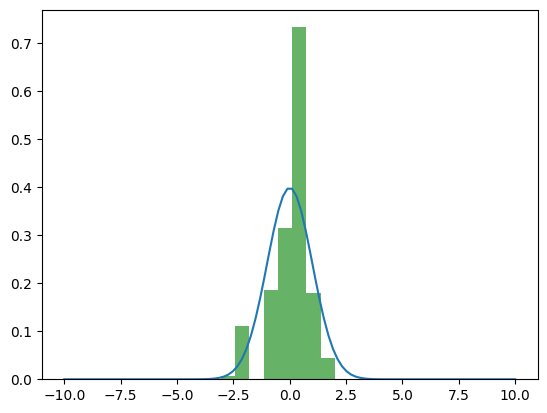

In [33]:
# setting
n = 100000 # sample size
n_trials=15  # number of trials of binomial distribution
prob = 0.5 + np.sqrt(1/12) # probability of success

# binomial distribution
mu = n_trials * prob
var = n_trials * prob * (1 - prob)

X = np.random.binomial(n_trials, p=prob, size=n)
# Y = (X - mu) / (var**0.5)
Y = (X - np.mean(X)) / (np.std(X))
plt.hist(Y, bins=int(np.floor(n_trials/2))+4, density=True, alpha=0.6, color='g')

sample_skew = skew(Y)
sample_kurt = kurtosis(Y, fisher=False)
print(
    f"Mean:{np.mean(Y):.3f}, "
    f"Var:{np.var(Y):.3f}, "
    f"Skew:{sample_skew:.3f}, "
    f"Kurt:{sample_kurt:.3f}"
)

# plot normal distribution
xs = np.linspace(-10, 10, 100)
plt.plot(xs, norm.pdf(xs, loc=0, scale=1))



# Mixture of Normals kurt = 3

In [ ]:
import sympy as sp
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt

def get_stats_moments(x, funx, x_interval, params=None, max_moment=4):
    """
    Computes symbolic raw moments, central moments, mean, variance,
    skewness, and kurtosis for ANY symbolic funx(x) on [a, b].
    
    - x : sympy Symbol
    - funx : sympy expression in x
    - x_interval : (a, b) integration limits
    - params : dict of substitutions {symbol: value} or None
    - max_moment : highest raw moment to compute (default 4)
    """

    a, b = x_interval

    # Apply parameter substitutions if needed
    f = funx
    if params is not None:
        f = f.subs(params)

    # ---------- RAW MOMENTS ----------
    raw_moments = {}
    for k in range(max_moment + 1):
        expr = x**k * f
        raw_moments[k] = sp.integrate(expr, (x, a, b))

    # Total mass (normalization constant)
    M = raw_moments[0]
    if M == 0:
        raise ValueError("Function has zero mass. Cannot compute stats.")

    # ---------- MEAN ----------
    mu = raw_moments[1] / M

    # ---------- CENTRAL MOMENTS ----------
    z = x - mu
    central_moments = {}
    for k in range(2, max_moment + 1):
        expr = (z**k) * f
        central_moments[k] = sp.integrate(expr, (x, a, b)) / M

    # Variance
    var = central_moments[2]
    sigma = sp.sqrt(var)

    # Skewness
    skew = central_moments[3] / sigma**3 if max_moment >= 3 else None

    # Kurtosis
    kurt = central_moments[4] / sigma**4 if max_moment >= 4 else None

    return {
        "mass": sp.simplify(M),
        "mean": sp.simplify(mu),
        "variance": sp.simplify(var),
        "skewness": sp.simplify(skew),
        "kurtosis": sp.simplify(kurt),
        "raw_moments": raw_moments,
        "central_moments": central_moments,
    }

def general_solver(expr, var, target, verbose=None):
    """
    Solve expr = target for 'var'.

    If verbose is None:
        → return full entries

    If verbose is a tuple like ("solution","real"):
        → return ONLY those keys per solution
    """

    def shrink(entry):
        # No verbose filtering → return full entry
        if verbose is None:
            return entry

        # If verbose is a tuple of field names, return only those
        return {k: entry[k] for k in verbose if k in entry}

    solutions = []

    # ------------------------------------------------------------
    # Case 1 — expr is NOT Piecewise
    # ------------------------------------------------------------
    if not isinstance(expr, sp.Piecewise):
        eq = sp.simplify(expr - target)
        sols = sp.solve(eq, var)

        for sol in sols:
            approx = float(sol.evalf()) if sol.is_real else None

            entry = {
                "solution": sol,
                "approx": approx,
                "branch_condition": True,
                "valid": True,
                "real": sol.is_real
            }

            solutions.append(shrink(entry))

        return solutions

    # ------------------------------------------------------------
    # Case 2 — expr IS Piecewise
    # ------------------------------------------------------------
    for branch_expr, cond in expr.args:
        eq = sp.simplify(branch_expr - target)
        sols = sp.solve(eq, var)

        for sol in sols:
            if isinstance(cond, bool):
                valid = cond
            else:
                try:
                    valid = bool(cond.subs(var, sol))
                except:
                    valid = None

            approx = float(sol.evalf()) if sol.is_real else None

            entry = {
                "solution": sol,
                "approx": approx,
                "branch_condition": cond,
                "valid": valid,
                "real": sol.is_real
            }

            solutions.append(shrink(entry))

    return solutions

In [35]:

# Parameters
inf = sp.oo
x = sp.symbols('x')
mu, sigma, theta = sp.symbols('mu sigma theta', positive=True)
a, b, c = sp.symbols('a b c', real=True)
alpha = sp.symbols('alpha', real=True)
p, q = sp.symbols('p q', positive=True)
c1 = sp.symbols('c1', real=True)   # for triweight parameter

w = sp.symbols('w', real=True)
mu1, mu2 = sp.symbols('mu1 mu2', real=True)
s1, s2 = sp.symbols('s1 s2', positive=True)

# Selector with domain-free functions
f_selector = {

    # 1. Gaussian
    "gaussian": (1/(sigma*sp.sqrt(2*sp.pi))) * sp.exp(-(x - mu)**2 / (2*sigma**2)),

    # 2. Piecewise test (kept as-is, but no domain constraint)
    "piecewise_test": sp.Piecewise(
        (x**2, x < 0),
        (sp.sin(x), True)   # no domain restriction
    ),

    # 3. Max-zero polynomial
    "max_zero": sp.Max(0, 1 - x + theta*x**2),

    # -----------------------------------------------------
    # NEW CLEAN CANDIDATE FAMILIES (no intervals inside)
    # -----------------------------------------------------

    # 4. Symmetric quadratic: f(x) = a + b x^2
    "quad_symmetric": a + b*x**2,

    # 5. General quadratic: f(x) = a + b x + c x^2
    "quad_general": a + b*x + c*x**2,

    # 6. Symmetric power: |x|^alpha
    "power_symmetric": sp.Abs(x)**alpha,

    # 7. Beta(p,q): domain-free shape (you restrict externally)
    "beta_pq": x**(p-1) * (1-x)**(q-1),

    # 8. Triweight-type kernel: (1 - c1*x^2)^3
    "triweight": (1 - c1*x**2)**3,

    # 9. Smooth kernel: (1 - x^2)^theta
    "power_kernel": (1 - x**2)**theta,
}

# 10. Gaussian mixture (bimodal-capable)
#     f(x) = w*N(mu1,s1^2) + (1-w)*N(mu2,s2^2)
f_selector["mixture_of_normals"] = \
    w * (1/(s1*sp.sqrt(2*sp.pi))) * sp.exp(-(x - mu1)**2 / (2*s1**2)) \
  + (1-w) * (1/(s2*sp.sqrt(2*sp.pi))) * sp.exp(-(x - mu2)**2 / (2*s2**2))


In [72]:
# Select function to analyze
fsym = f_selector["mixture_of_normals"]
funxinterval = [-inf, inf]

fsym = fsym.subs({
    mu1: -1,
    mu2: 1,
    s1: 1,
    s2: 1,
})

# Get Stats and Moments Symbolically
moments = get_stats_moments(x, fsym, funxinterval)

display( 
sp.simplify(moments["skewness"]),
sp.simplify(moments["kurtosis"])
)

# Solve for theta such that kurtosis = 3
kurt_pw = sp.simplify(moments["kurtosis"])

solutions = general_solver(sp.simplify(moments["kurtosis"]), w, 3, verbose=("solution", "real"))
solutions[2]["solution"]

-8*w*(2*w**2 - 3*w + 1)/(-4*w**2 + 4*w + 1)**(3/2)

(-48*w**4 + 96*w**3 - 88*w**2 + 40*w + 3)/(16*w**4 - 32*w**3 + 8*w**2 + 8*w + 1)

1/2 - sqrt(3)/6

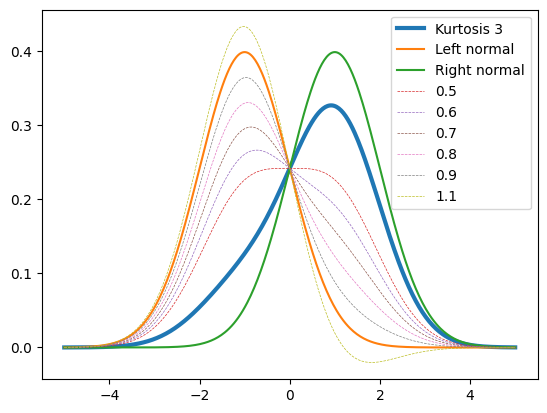

In [100]:
# Turn symbolic into numeric function
f = fsym.subs({w: solutions[2]["solution"]})
# f = fsym.subs({w: 0.5})
f_num = sp.lambdify(x, f, 'numpy')

# Plot With Subs
xinterval = [-5, 5]
division = 400
xs = np.linspace(xinterval[0], xinterval[1], division)

# --- Append this block ---

# Define symbolic components (left and right normals)
N_left = (1/(s1*sp.sqrt(2*sp.pi))) * sp.exp(-(x - mu1)**2 / (2*s1**2))
N_right = (1/(s2*sp.sqrt(2*sp.pi))) * sp.exp(-(x - mu2)**2 / (2*s2**2))

# Substitute same parameters (keep w consistent)
subs_params = {
    mu1: -1,
    mu2:  1,
    s1:  1,
    s2:  1
}

# Numeric functions
left_num  = sp.lambdify(x, N_left.subs(subs_params), 'numpy')
right_num = sp.lambdify(x, N_right.subs(subs_params), 'numpy')

# Plot all on the same graph
plt.plot(xs, f_num(xs), label="Kurtosis 3", linewidth=3)
plt.plot(xs, left_num(xs), label="Left normal")
plt.plot(xs, right_num(xs), label="Right normal")

for wi in [0.5, 0.6, 0.7, 0.8, 0.9, 1.1]:
    f_num = sp.lambdify(x, fsym.subs({w: wi}), 'numpy')
    plt.plot(xs, f_num(xs), '--', label=str(wi), linewidth=0.5)

plt.legend()

plt.legend()
plt.show()


# General Bimodal Gaussian Mixture

In [3]:
import sympy as sp
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt

def bimodal_mixture(w=0.5, mu1=-1, mu2=1, s1=1, s2=1):
    mixture = w * (1/(s1*sp.sqrt(2*sp.pi))) * sp.exp(-(x - mu1)**2 / (2*s1**2)) \
  + (1-w) * (1/(s2*sp.sqrt(2*sp.pi))) * sp.exp(-(x - mu2)**2 / (2*s2**2))
    return mixture

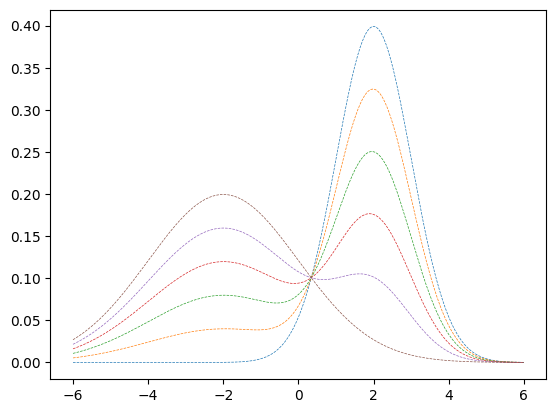

In [7]:
w, mu1, mu2, s1, s2 = sp.symbols('w mu1 mu2 s1 s2', real=True)
x = sp.Symbol('x')

pdf = bimodal_mixture(w, mu1, mu2, s1, s2)

pdf = pdf.subs({
    mu1: -2,
    mu2: 2,
    s1: 2,
    s2: 1,
})

xs = np.linspace(-6, 6, 400)
n=5
for wi in [i/n for i in range(0, n+1)]:
    f_num = sp.lambdify(x, pdf.subs({w: wi}), 'numpy')
    plt.plot(xs, f_num(xs), '--', label=str(wi), linewidth=0.5)